In [1]:
import tensorflow as tf
import numpy as np

from tensorflow.keras.layers import Input
from tensorflow.keras.layers import Conv2D
from tensorflow.keras.layers import MaxPooling2D
from tensorflow.keras.layers import Dropout 
from tensorflow.keras.layers import Conv2DTranspose
from tensorflow.keras.layers import concatenate

from test_utils import summary, comparator


# Download datset

In [1]:
## uncomment code and download dataset and rename folder to dataset

In [2]:
"""
import kagglehub

# Download latest version
path = kagglehub.dataset_download("shivamaggarwal513/semantic-segmentation-car-driving")

print("Path to dataset files:", path)
"""

'\nimport kagglehub\n\n# Download latest version\npath = kagglehub.dataset_download("shivamaggarwal513/semantic-segmentation-car-driving")\n\nprint("Path to dataset files:", path)\n'

In [3]:
import os
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

import imageio

import matplotlib.pyplot as plt
%matplotlib inline

path = ''
image_path = os.path.join(path, 'dataset/versions/1/x-rgb/')
mask_path = os.path.join(path, 'dataset/versions/1/y-mask/')
image_list = os.listdir(image_path)
mask_list = os.listdir(mask_path)
image_list = [image_path+i for i in image_list]
mask_list = [mask_path+i for i in mask_list]

In [4]:
len(image_list)

1060

C:\Users\pc\AppData\Local\Temp\ipykernel_6984\3468410390.py:2: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  img = imageio.imread(image_list[N])
C:\Users\pc\AppData\Local\Temp\ipykernel_6984\3468410390.py:3: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  mask = imageio.imread(mask_list[N])


Text(0.5, 1.0, 'Segmentation')

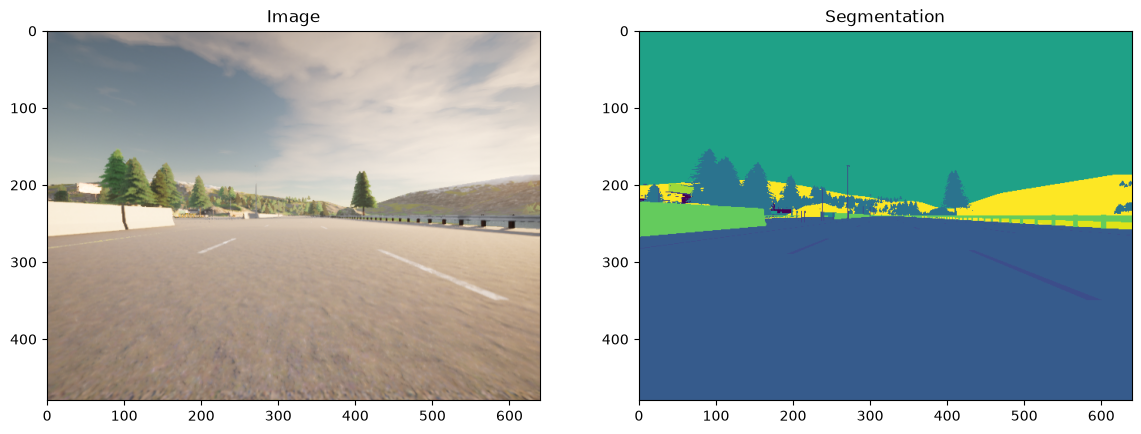

In [5]:
N = 3
img = imageio.imread(image_list[N])
mask = imageio.imread(mask_list[N])
#mask = np.array([max(mask[i, j]) for i in range(mask.shape[0]) for j in range(mask.shape[1])]).reshape(img.shape[0], img.shape[1])

fig, arr = plt.subplots(1, 2, figsize=(14, 10))
arr[0].imshow(img)
arr[0].set_title('Image')
arr[1].imshow(mask[:, :, 0])
arr[1].set_title('Segmentation')

In [5]:
image_list_ds = tf.data.Dataset.list_files(image_list, shuffle=False)
mask_list_ds = tf.data.Dataset.list_files(mask_list, shuffle=False)

for path in zip(image_list_ds.take(3), mask_list_ds.take(3)):
    print(path)

(<tf.Tensor: shape=(), dtype=string, numpy=b'semantic-segmentation-car-driving\\versions\\1\\x-rgb\\000026.png'>, <tf.Tensor: shape=(), dtype=string, numpy=b'semantic-segmentation-car-driving\\versions\\1\\y-mask\\000026.png'>)
(<tf.Tensor: shape=(), dtype=string, numpy=b'semantic-segmentation-car-driving\\versions\\1\\x-rgb\\000027.png'>, <tf.Tensor: shape=(), dtype=string, numpy=b'semantic-segmentation-car-driving\\versions\\1\\y-mask\\000027.png'>)
(<tf.Tensor: shape=(), dtype=string, numpy=b'semantic-segmentation-car-driving\\versions\\1\\x-rgb\\000028.png'>, <tf.Tensor: shape=(), dtype=string, numpy=b'semantic-segmentation-car-driving\\versions\\1\\y-mask\\000028.png'>)


In [6]:
image_filenames = tf.constant(image_list)
masks_filenames = tf.constant(mask_list)

dataset = tf.data.Dataset.from_tensor_slices((image_filenames, masks_filenames))

for image, mask in dataset.take(1):
    print(image)
    print(mask)

tf.Tensor(b'semantic-segmentation-car-driving/versions/1/x-rgb/000026.png', shape=(), dtype=string)
tf.Tensor(b'semantic-segmentation-car-driving/versions/1/y-mask/000026.png', shape=(), dtype=string)


In [7]:
def process_path(image_path, mask_path):
    img = tf.io.read_file(image_path)
    img = tf.image.decode_png(img, channels=3)
    img = tf.image.convert_image_dtype(img, tf.float32)

    mask = tf.io.read_file(mask_path)
    mask = tf.image.decode_png(mask, channels=3)
    mask = tf.math.reduce_max(mask, axis=-1, keepdims=True)
    return img, mask

def preprocess(image, mask):
    input_image = tf.image.resize(image, (96, 128), method='nearest')
    input_mask = tf.image.resize(mask, (96, 128), method='nearest')

    input_image = input_image / 255.

    return input_image, input_mask

image_ds = dataset.map(process_path)
processed_image_ds = image_ds.map(preprocess)

In [8]:
def conv_block(inputs=None, n_filters=32, dropout_prob=0, max_pooling=True):
    x = Conv2D(n_filters, kernel_size=(3, 3),padding='same',kernel_initializer='he_normal', activation='relu')(inputs)
    x = Conv2D(n_filters, kernel_size=(3, 3),padding='same',kernel_initializer='he_normal', activation='relu')(x)

    if dropout_prob >0:
        x=Dropout(dropout_prob)(x)
    if max_pooling==True:
        next_layer=MaxPooling2D(2,strides=2)(x)
        
    else:
        next_layer=x
        
    skip_connection=x
    return   next_layer, skip_connection
    

In [9]:
input_size=(96, 128, 3)
n_filters = 32
inputs = Input(input_size)
cblock1 = conv_block(inputs, n_filters * 1)
model1 = tf.keras.Model(inputs=inputs, outputs=cblock1)

output1 = [['InputLayer', (None, 96, 128, 3), 0],
            ['Conv2D', (None, 96, 128, 32), 896, 'same', 'relu', 'HeNormal'],
            ['Conv2D', (None, 96, 128, 32), 9248, 'same', 'relu', 'HeNormal'],
            ['MaxPooling2D', (None, 48, 64, 32), 0, (2, 2)]]

print('Block 1:')
for layer in summary(model1):
    print(layer)

comparator(summary(model1), output1)

inputs = Input(input_size)
cblock1 = conv_block(inputs, n_filters * 32, dropout_prob=0.1, max_pooling=True)
model2 = tf.keras.Model(inputs=inputs, outputs=cblock1)

output2 = [['InputLayer', (None, 96, 128, 3), 0],
            ['Conv2D', (None, 96, 128, 1024), 28672, 'same', 'relu', 'HeNormal'],
            ['Conv2D', (None, 96, 128, 1024), 9438208, 'same', 'relu', 'HeNormal'],
            ['Dropout', (None, 96, 128, 1024), 0, 0.1],
            ['MaxPooling2D', (None, 48, 64, 1024), 0, (2, 2)]]
           
print('\nBlock 2:')   
for layer in summary(model2):
    print(layer)
    
comparator(summary(model2), output2)

Block 1:
['InputLayer', (None, 96, 128, 3), 0]
['Conv2D', (None, 96, 128, 32), 896, 'same', 'relu', 'HeNormal']
['Conv2D', (None, 96, 128, 32), 9248, 'same', 'relu', 'HeNormal']
['MaxPooling2D', (None, 48, 64, 32), 0, (2, 2)]
All tests passed!

Block 2:
['InputLayer', (None, 96, 128, 3), 0]
['Conv2D', (None, 96, 128, 1024), 28672, 'same', 'relu', 'HeNormal']
['Conv2D', (None, 96, 128, 1024), 9438208, 'same', 'relu', 'HeNormal']
['Dropout', (None, 96, 128, 1024), 0, 0.1]
['MaxPooling2D', (None, 48, 64, 1024), 0, (2, 2)]
All tests passed!


In [10]:
def upsampling_block(expansive_input, contractive_input, n_filters=32):
    x=Conv2DTranspose(n_filters,kernel_size=(3,3),strides=(2, 2),padding="same")(expansive_input)
    merge=concatenate([x,contractive_input],axis=3)
    conv = Conv2D(n_filters, kernel_size=(3, 3),padding='same',kernel_initializer='he_normal', activation='relu')(merge)
    conv = Conv2D(n_filters, kernel_size=(3, 3),padding='same',kernel_initializer='he_normal', activation='relu')(conv)

    
    return conv

In [11]:
input_size1=(12, 16, 256)
input_size2 = (24, 32, 128)
n_filters = 32
expansive_inputs = Input(input_size1)
contractive_inputs =  Input(input_size2)
cblock1 = upsampling_block(expansive_inputs, contractive_inputs, n_filters * 1)
model1 = tf.keras.Model(inputs=[expansive_inputs, contractive_inputs], outputs=cblock1)

output1 = [['InputLayer', (None, 12, 16, 256), 0],
            ['Conv2DTranspose', (None, 24, 32, 32), 73760],
            ['InputLayer', (None, 24, 32, 128), 0],
            ['Concatenate', (None, 24, 32, 160), 0],
            ['Conv2D', (None, 24, 32, 32), 46112, 'same', 'relu', 'HeNormal'],
            ['Conv2D', (None, 24, 32, 32), 9248, 'same', 'relu', 'HeNormal']]

print('Block 1:')
for layer in summary(model1):
    print(layer)

comparator(summary(model1), output1)

Block 1:
['InputLayer', (None, 12, 16, 256), 0]
['Conv2DTranspose', (None, 24, 32, 32), 73760]
['InputLayer', (None, 24, 32, 128), 0]
['Concatenate', (None, 24, 32, 160), 0]
['Conv2D', (None, 24, 32, 32), 46112, 'same', 'relu', 'HeNormal']
['Conv2D', (None, 24, 32, 32), 9248, 'same', 'relu', 'HeNormal']
All tests passed!


In [12]:
def unet_model(input_size=(96, 128, 3), n_filters=32, n_classes=23):
    inputs = Input(input_size)

    conv1,skip_connec1=conv_block(inputs=inputs, n_filters=n_filters*1, dropout_prob=0, max_pooling=True)
    conv2,skip_connec2=conv_block(inputs=conv1, n_filters=n_filters*2, dropout_prob=0, max_pooling=True)
    conv3,skip_connec3=conv_block(inputs=conv2, n_filters=n_filters*4, dropout_prob=0, max_pooling=True)
    conv4,skip_connec4=conv_block(inputs=conv3, n_filters=n_filters*8, dropout_prob=0.3, max_pooling=True)
    conv5,skip_connec5=conv_block(inputs=conv4, n_filters=n_filters*16, dropout_prob=0.3, max_pooling=False)
    ublock1=upsampling_block(conv5, skip_connec4, n_filters=n_filters*8)
    ublock2=upsampling_block(ublock1, skip_connec3, n_filters=n_filters*4)
    ublock3=upsampling_block(ublock2, skip_connec2, n_filters=n_filters*2)
    ublock4=upsampling_block(ublock3, skip_connec1, n_filters=n_filters*1)
    conv9 = Conv2D(n_filters, kernel_size=(3, 3),padding='same',kernel_initializer='he_normal', activation='relu')(ublock4)
    conv10 = Conv2D(n_classes, kernel_size=(1, 1),padding='same')(conv9)
    model = tf.keras.Model(inputs=inputs, outputs=conv10)
    return model

In [13]:
import outputs
img_height = 96
img_width = 128
num_channels = 3

unet = unet_model((img_height, img_width, num_channels))
comparator(summary(unet), outputs.unet_model_output)


All tests passed!


In [14]:
img_height = 96
img_width = 128
num_channels = 3

unet = unet_model((img_height, img_width, num_channels))

In [15]:
unet.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)    │ (None, 96, 128, 3)        │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_26 (Conv2D)            │ (None, 96, 128, 32)       │             896 │ input_layer_5[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_27 (Conv2D)            │ (None, 96, 128, 32)       │           9,248 │ conv2d_26[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_6               │ (None, 48, 64, 32)        │               0 │ conv2d_27[0][0]            │
│ (MaxPooling2D)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_28 (Conv2D)            │ (None, 48, 64, 64)        │          18,496 │ max_pooling2d_6[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_29 (Conv2D)            │ (None, 48, 64, 64)        │          36,928 │ conv2d_28[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_7               │ (None, 24, 32, 64)        │               0 │ conv2d_29[0][0]            │
│ (MaxPooling2D)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_30 (Conv2D)            │ (None, 24, 32, 128)       │          73,856 │ max_pooling2d_7[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_31 (Conv2D)            │ (None, 24, 32, 128)       │         147,584 │ conv2d_30[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_8               │ (None, 12, 16, 128)       │               0 │ conv2d_31[0][0]            │
│ (MaxPooling2D)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_32 (Conv2D)            │ (None, 12, 16, 256)       │         295,168 │ max_pooling2d_8[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_33 (Conv2D)            │ (None, 12, 16, 256)       │         590,080 │ conv2d_32[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout_3 (Dropout)           │ (None, 12, 16, 256)       │               0 │ conv2d_33[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_9               │ (None, 6, 8, 256)         │               0 │ dropout_3[0][0]            │
│ (MaxPooling2D)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_34 (Conv2D)            │ (None, 6, 8, 512)         │       1,180,160 │ max_pooling2d_9[0][0]      │
├───────────────────────────────┼───────────────────────────┼───────────────

 Total params: 8,640,471 (32.96 MB)

 Trainable params: 8,640,471 (32.96 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
unet.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

In [17]:
def display(display_list):
    plt.figure(figsize=(15, 15))

    title = ['Input Image', 'True Mask', 'Predicted Mask']

    for i in range(len(display_list)):
        plt.subplot(1, len(display_list), i+1)
        plt.title(title[i])
        plt.imshow(tf.keras.preprocessing.image.array_to_img(display_list[i]))
        plt.axis('off')
    plt.show()

(480, 640, 1)


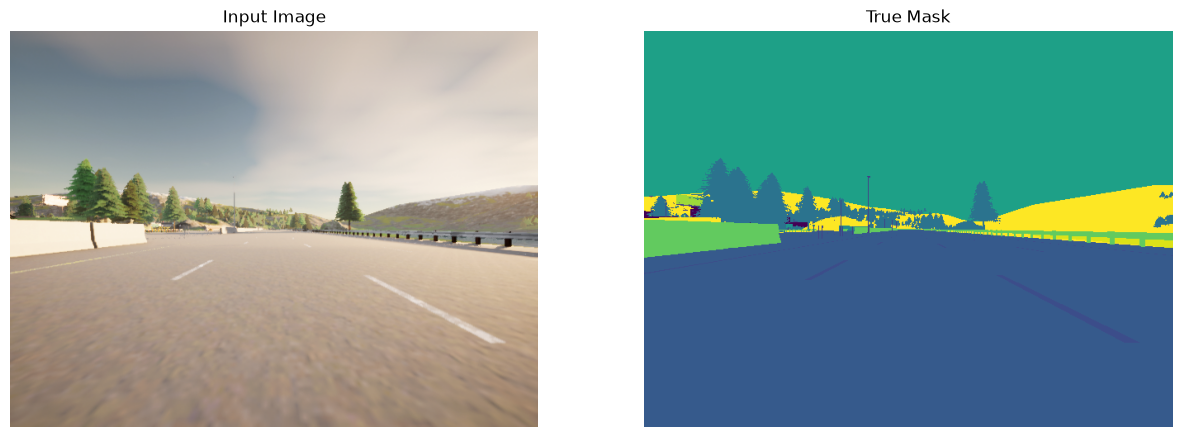

In [18]:
for image, mask in image_ds.take(1):
    sample_image, sample_mask = image, mask
    print(mask.shape)
display([sample_image, sample_mask])

(96, 128, 1)


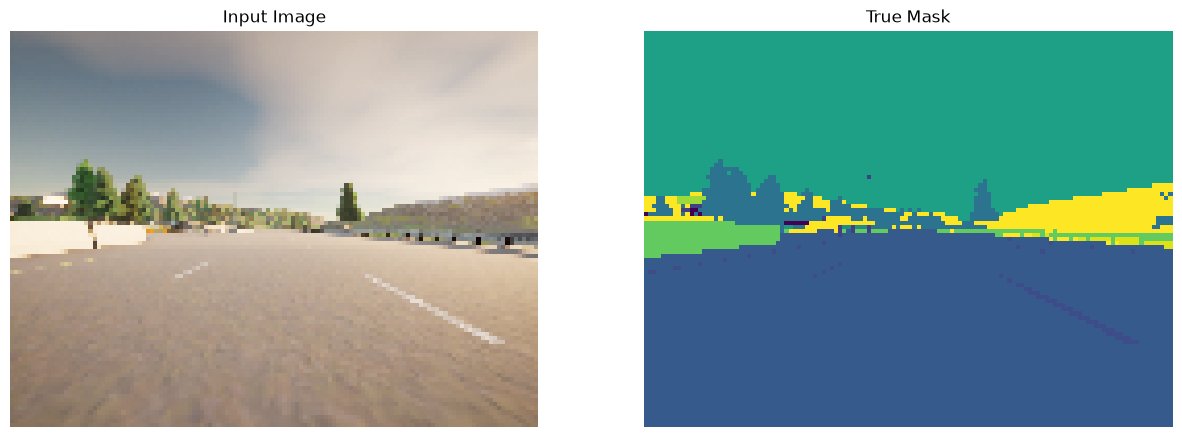

In [19]:
for image, mask in processed_image_ds.take(1):
    sample_image, sample_mask = image, mask
    print(mask.shape)
display([sample_image, sample_mask])

In [20]:
EPOCHS = 40
VAL_SUBSPLITS = 5
BUFFER_SIZE = 500
BATCH_SIZE = 32
processed_image_ds.batch(BATCH_SIZE)
train_dataset = processed_image_ds.cache().shuffle(BUFFER_SIZE).batch(BATCH_SIZE)
print(processed_image_ds.element_spec)
model_history = unet.fit(train_dataset, epochs=EPOCHS)

(TensorSpec(shape=(96, 128, 3), dtype=tf.float32, name=None), TensorSpec(shape=(96, 128, 1), dtype=tf.uint8, name=None))
Epoch 1/40


C:\Users\pc\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


34/34 ━━━━━━━━━━━━━━━━━━━━ 63s 2s/step - accuracy: 0.3804 - loss: 2.7918
Epoch 2/40
34/34 ━━━━━━━━━━━━━━━━━━━━ 56s 2s/step - accuracy: 0.4488 - loss: 1.6014
Epoch 3/40
34/34 ━━━━━━━━━━━━━━━━━━━━ 56s 2s/step - accuracy: 0.7124 - loss: 1.0245
Epoch 4/40
34/34 ━━━━━━━━━━━━━━━━━━━━ 55s 2s/step - accuracy: 0.7577 - loss: 0.7976
Epoch 5/40
34/34 ━━━━━━━━━━━━━━━━━━━━ 55s 2s/step - accuracy: 0.7611 - loss: 0.7640
Epoch 6/40
34/34 ━━━━━━━━━━━━━━━━━━━━ 53s 2s/step - accuracy: 0.7730 - loss: 0.7217
Epoch 7/40
34/34 ━━━━━━━━━━━━━━━━━━━━ 50s 1s/step - accuracy: 0.7954 - loss: 0.6470
Epoch 8/40
34/34 ━━━━━━━━━━━━━━━━━━━━ 52s 2s/step - accuracy: 0.8068 - loss: 0.6016
Epoch 9/40
34/34 ━━━━━━━━━━━━━━━━━━━━ 52s 2s/step - accuracy: 0.7433 - loss: 1.0715
Epoch 10/40
34/34 ━━━━━━━━━━━━━━━━━━━━ 51s 1s/step - accuracy: 0.7710 - loss: 0.7830
Epoch 11/40
34/34 ━━━━━━━━━━━━━━━━━━━━ 51s 1s/step - accuracy: 0.7767 - loss: 0.7347
Epoch 12/40
34/34 ━━━━━━━━━━━━━━━━━━━━ 51s 2s/step - accuracy: 0.7817 - loss: 0.7068


In [23]:
unet.save("model.keras")

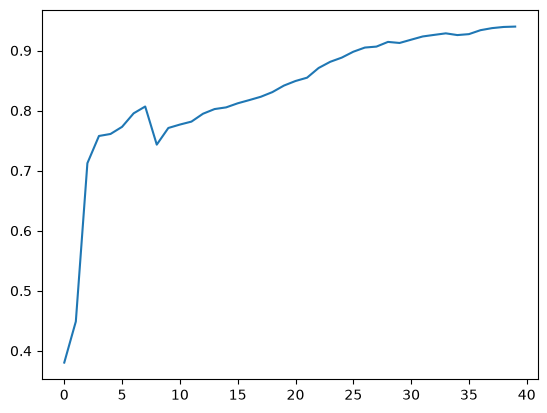

In [24]:
plt.plot(model_history.history["accuracy"])

In [57]:
from PIL import Image, ImageOps
import keras
import numpy as np

In [76]:
def display_mask(mask_):
    """Quick utility to display a model's prediction."""
    mask = np.argmax(mask_, axis=-1)
    mask = np.expand_dims(mask, axis=-1)
    img = ImageOps.autocontrast(keras.utils.array_to_img(mask))
    return img


In [77]:
model = keras.saving.load_model("model.keras")


C:\Users\pc\AppData\Roaming\Python\Python311\site-packages\keras\src\saving\saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'rm_sprop', because it has 50 variables whereas the saved optimizer has 98 variables. 
  saveable.load_own_variables(store)


In [79]:
def show_predictions(model,dataset=None, num=1):
    """
    Displays the first image of each of the num batches
    """
    if dataset:
        for image, mask in dataset.take(num):
            pred_mask = model.predict(image)
            mask_img=display_mask(pred_mask[0])
            mask_img=np.asarray(mask_img)
            mask_img=mask_img.reshape((mask_img.shape[0], mask_img.shape[1], 1))


            display([image[0], mask[0], mask_img])
    else:
        display([sample_image, sample_mask,
             create_mask(unet.predict(sample_image[tf.newaxis, ...]))])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 482ms/step


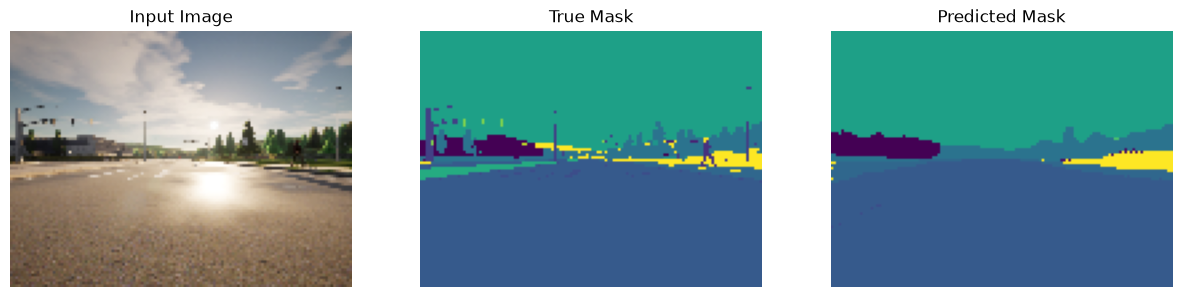

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 343ms/step


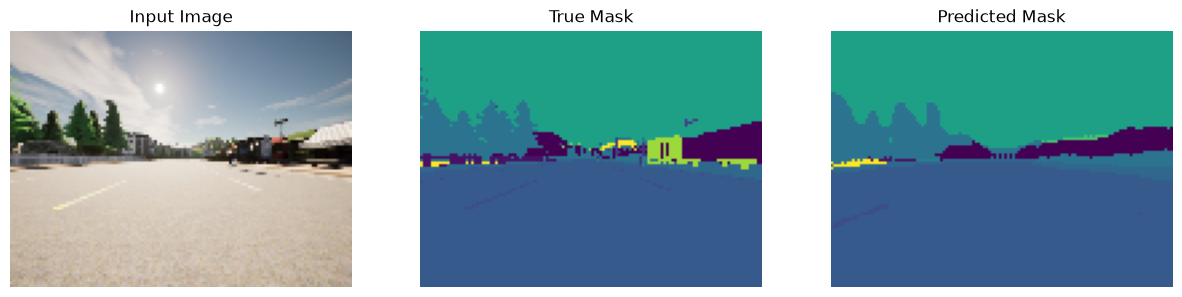

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 343ms/step


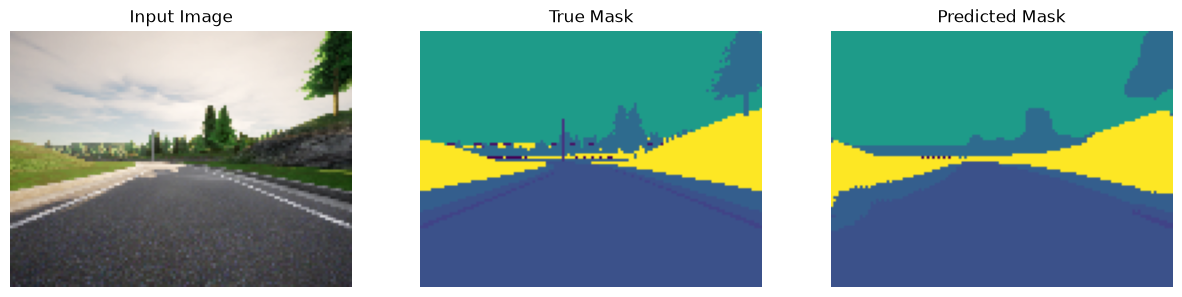

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 332ms/step


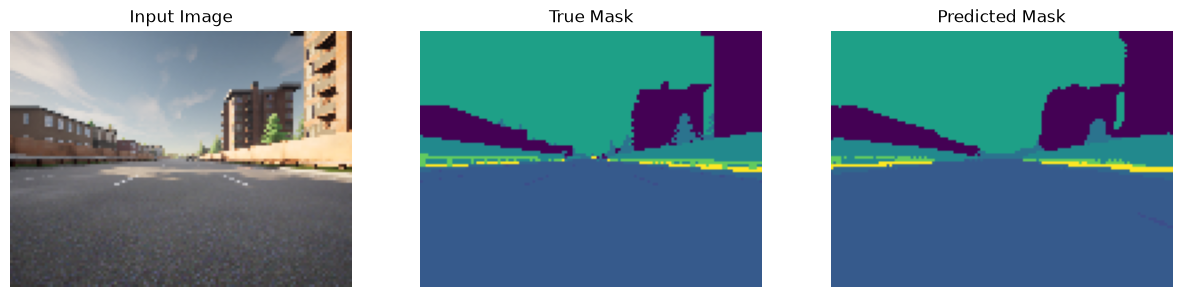

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 330ms/step


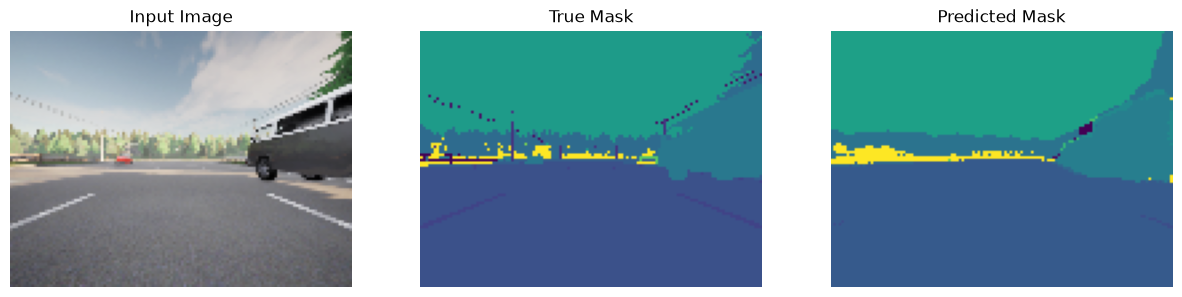

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 343ms/step


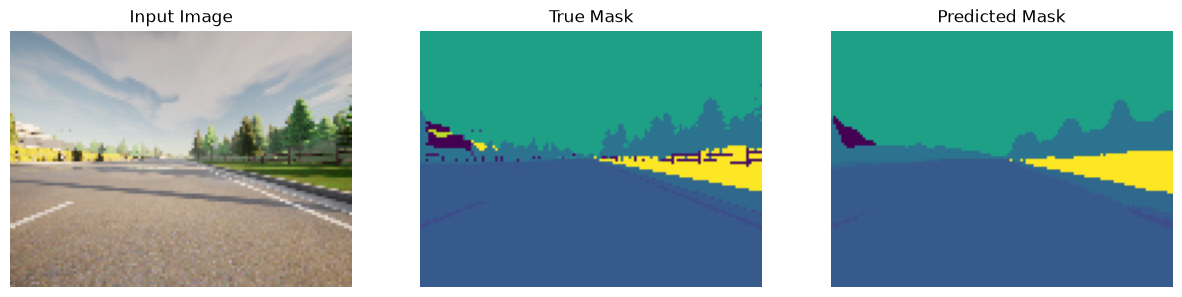

In [80]:
show_predictions(model,train_dataset, 6)